# 06 · Imbalance Comparison

Only 11.7% of clients subscribe. The course (lesson 11) gives four options: oversample the minority class, create synthetic
minority rows (SMOTE / SMOTENC), overweight the minority class (`class_weight`), or change the threshold.
This notebook compares the first three on the **training set with cross-validation**, so the test set stays untouched.

Resampling sits inside imblearn's `make_pipeline`, so it only ever touches the training folds.

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, linear_preprocessor, tree_preprocessor, RANDOM_STATE, BINARY_COLS

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
best = json.load(open('../results/best_params.json'))
gb_params = {k.replace('model__', ''): v for k, v in best['gradient_boosting'].items()}
print('Gradient Boosting params:', gb_params)

Gradient Boosting params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}


## Set-up

- **SMOTENC** (not plain SMOTE) because the data mixes numeric and categorical columns; it runs **before** one-hot encoding, as in the lesson 11 lab.
- Oversampling brings the minority class up to **50%** of the majority class (`sampling_strategy=0.5`).
- 3-fold stratified cross-validation; metrics at the default 0.5 threshold, plus ROC-AUC.

In [2]:
numeric = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
categorical = [c for c in X_train.columns if c not in numeric]   # includes the 0/1 columns, so they stay 0/1
print('categorical for SMOTENC:', categorical)

def ros():
    return RandomOverSampler(sampling_strategy=0.5, random_state=RANDOM_STATE)

def smotenc():
    return SMOTENC(categorical_features=categorical, sampling_strategy=0.5, random_state=RANDOM_STATE)

lr = lambda **kw: LogisticRegression(max_iter=2000, C=0.1, **kw)
gb = lambda: GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params)

setups = {
    ('Logistic Regression', 'none'):          make_pipeline(linear_preprocessor(), lr()),
    ('Logistic Regression', 'class_weight'):  make_pipeline(linear_preprocessor(), lr(class_weight='balanced')),
    ('Logistic Regression', 'RandomOverSampler'): make_pipeline(ros(), linear_preprocessor(), lr()),
    ('Logistic Regression', 'SMOTENC'):       make_pipeline(smotenc(), linear_preprocessor(), lr()),
    ('Gradient Boosting', 'none'):            make_pipeline(tree_preprocessor(), gb()),
    ('Gradient Boosting', 'RandomOverSampler'): make_pipeline(ros(), tree_preprocessor(), gb()),
    ('Gradient Boosting', 'SMOTENC'):         make_pipeline(smotenc(), tree_preprocessor(), gb()),
}

categorical for SMOTENC: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_bin', 'previous_bin', 'pdays_bin']


In [3]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = ['roc_auc', 'balanced_accuracy', 'recall', 'precision', 'f1']
rows = []
for (model, method), pipe in setups.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'model': model, 'imbalance_method': method,
                 **{m: s[f'test_{m}'].mean() for m in scoring}})
    print(f'{model:20s} {method:18s} ROC-AUC {rows[-1]["roc_auc"]:.4f}  recall {rows[-1]["recall"]:.3f}')
imb = pd.DataFrame(rows).round(4)
imb

Logistic Regression  none               ROC-AUC 0.7710  recall 0.173


Logistic Regression  class_weight       ROC-AUC 0.7718  recall 0.626


Logistic Regression  RandomOverSampler  ROC-AUC 0.7715  recall 0.432


Logistic Regression  SMOTENC            ROC-AUC 0.7443  recall 0.425


Gradient Boosting    none               ROC-AUC 0.7975  recall 0.241


Gradient Boosting    RandomOverSampler  ROC-AUC 0.7985  recall 0.479


Gradient Boosting    SMOTENC            ROC-AUC 0.7760  recall 0.455


,model,imbalance_method,roc_auc,balanced_accuracy,recall,precision,f1
0,Logistic Regression,none,0.7710,0.5802,0.1730,0.6470,0.2729
1,Logistic Regression,class_weight,0.7718,0.7085,0.6256,0.2844,0.3910
2,Logistic Regression,RandomOverSampler,0.7715,0.6812,0.4318,0.4516,0.4415
3,Logistic Regression,SMOTENC,0.7443,0.6655,0.4247,0.3755,0.3984
4,Gradient Boosting,none,0.7975,0.6104,0.2408,0.6156,0.3462
5,Gradient Boosting,RandomOverSampler,0.7985,0.7049,0.4791,0.4778,0.4784
6,Gradient Boosting,SMOTENC,0.7760,0.6894,0.4550,0.4421,0.4483


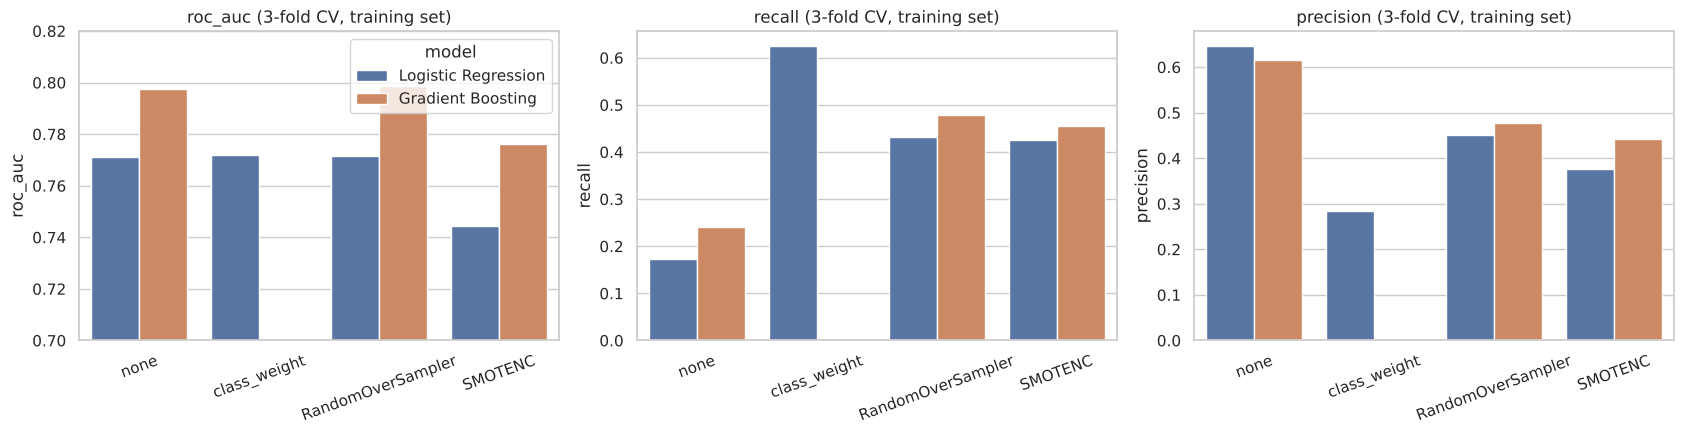

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ['roc_auc', 'recall', 'precision']):
    sns.barplot(data=imb, x='imbalance_method', y=metric, hue='model', ax=ax)
    ax.set_title(f'{metric} (3-fold CV, training set)')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
    if metric == 'roc_auc':
        ax.set_ylim(0.7, 0.82)
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.tight_layout(); plt.show()

## What this shows

- **Class weights and random oversampling leave ROC-AUC unchanged** (Logistic Regression 0.771–0.772; Gradient Boosting 0.798–0.799). Balancing does not make the model rank clients better.
- **SMOTENC actually lowers ROC-AUC** (Logistic Regression 0.744, Gradient Boosting 0.776): its synthetic clients add noise rather than signal on this data.
- What balancing changes is **recall vs precision at the 0.5 threshold**. Gradient Boosting goes from recall 0.24 / precision 0.62 (no handling) to 0.48 / 0.48 (oversampling): the model simply flags more clients.
- Moving the threshold (lesson 10, and option 4 in lesson 11) does the same job **without fake rows** and lets the bank pick the trade-off directly.

**Decision:** keep **Gradient Boosting without resampling** (best ROC-AUC, simplest pipeline) and handle the imbalance by **tuning the threshold** in notebook 07.
Logistic Regression with `class_weight='balanced'` stays as the readable model for explaining drivers.

In [5]:
imb.to_csv('../results/imbalance_cv.csv', index=False)